In [1]:
import numpy as np
import healpy as hp
from healpy.newvisufunc import projview
from astropy.table import Table

import matplotlib
from matplotlib import pyplot as plt

from Corrfunc import mocks
from Corrfunc.utils import convert_rp_pi_counts_to_wp
from scipy import constants
from scipy import stats
import scipy.interpolate as interp
from random import sample
import matplotlib.gridspec as gridspec
from Corrfunc import theory
from astropy.cosmology import FlatLambdaCDM
from Corrfunc.utils import convert_3d_counts_to_cf
import astropy.cosmology.units as cu
import astropy.units as u
import site
site.addsitedir('/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts') 
import quaia
import quaia_debug
from astropy.coordinates import SkyCoord
import matplotlib.gridspec as gridspec
import seaborn as sns
from matplotlib.colors import LogNorm
import os
import matplotlib.patches as mpatches
import pyccl as ccl
from matplotlib.lines import Line2D
from astropy import constants as const
import importlib
from os.path import dirname, abspath, join as pjoin
import Corrfunc
from Corrfunc.io import read_catalog

In [2]:
matplotlib.rcParams['ytick.labelsize'] = 18
matplotlib.rcParams['xtick.labelsize'] = 18
matplotlib.rcParams['axes.labelsize'] = 22
matplotlib.rcParams['legend.fontsize'] = 18
matplotlib.rcParams['axes.titlesize'] = 20

# Compute $w_p$
## Parameters

In [3]:
G_hi = 20.5

In [4]:
nthreads = 18

In [5]:
h_planck20 = 0.674

In [6]:
H0_planck20 = h_planck20*100 * u.km/u.s/u.Mpc

In [7]:
z_bins = np.array([0.0, 1.0, 2.0, 3.0, 4.0])
z_array = range(len(z_bins)-1)
mask = 0.5

In [8]:
Omega_m_planck20 = 0.315

In [9]:
cosmo_planck20 = ccl.Cosmology(Omega_c=0.265, Omega_b=0.049, h=h_planck20, n_s=0.95, sigma8=0.8)

In [10]:
cmap_qq = plt.get_cmap('Oranges')(np.linspace(0.333, 0.999, len(z_array)))
cmap_mm = plt.get_cmap('Greens')(np.linspace(0.333, 0.999, len(z_array)))
cmap_b = plt.get_cmap('Greys')(np.linspace(0.333, 0.999, len(z_array)))
cmaps = [cmap_qq, cmap_mm]

In [11]:
orange = plt.get_cmap('Oranges')((0.333+0.999)/2)
green = plt.get_cmap('Greens')((0.333+0.999)/2)
colors = [orange, green]

In [12]:
# Create the bins array
rpmin = 0.15 # 0.5 # 0.1 # start higher
rpmax = 240 # 120 #85 # 60.0 # 20.0 
nbins = 20 
rpbins = np.logspace(np.log10(rpmin), np.log10(rpmax), nbins + 1) # Mpc/h https://github.com/manodeep/Corrfunc/issues/202
scale = 'log'

In [13]:
pimax = 80 # 40 # 5000.0 # 40.0

## Original version

In [14]:
wp_zbin_percentile = []
rpavg_zbin_percentile = []
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask)
    wp_zbin_i, rpavg_zbin_i, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Omega_m_planck20, h = h_planck20,
                                                      nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
    wp_zbin_percentile.append(wp_zbin_i)
    rpavg_zbin_percentile.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


[Warning] The CPU supports AVX512F but the compiler does not.  Can you try another compiler?
/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0: 0.37              179640 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin3.0zmax4.0: 0.46              19252 vs 35630


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


## Debugged version

In [ ]:
wp_debug = []
rpavg_debug = []
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask)
    wp_zbin_i, rpavg_zbin_i, qq, qr = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Omega_m_planck20, h = h_planck20,
                                                      nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
    wp_debug.append(wp_zbin_i)
    rpavg_debug.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


## Check if comoving_dist() is the issue
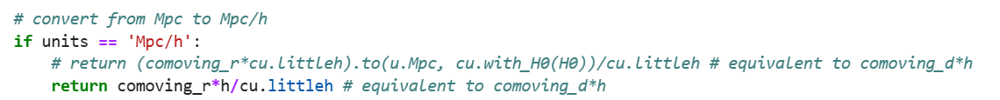

In [ ]:
fig = plt.figure(figsize = (10, 8))
# gs = gridspec.GridSpec(2, 2, height_ratios = [1, 0.5], hspace = 0, wspace = 0)

labels_cf = ['Original', 'Debugged']
# for i in range(len(Omega_m_array)):
    
#     ax1 = fig.add_subplot(gs[i])
#     ax2 = fig.add_subplot(gs[i+2])

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = r'Original', 
                 color = cmap_qq[j])
    plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = r'Debugged', linestyle = '--',
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])
# plt.legend()

custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

In [18]:
(quaia.comoving_dist(1, h = h_planck20, Om0 = Omega_m_planck20)).to(u.Mpc, cu.with_H0(H0_planck20))

<Quantity 3401.26291735 Mpc>

In [19]:
quaia_debug.comoving_dist(1, h = h_planck20, Om0 = Omega_m_planck20, Ob0 = cosmo_planck20['Omega_b'], units = 'Mpc')

<Quantity 3401.26291735 Mpc>

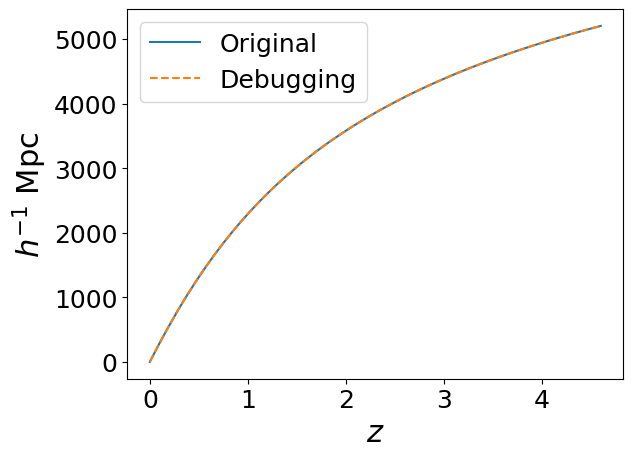

In [20]:
z = np.linspace(0, 4.6)
plt.plot(z, quaia.comoving_dist(z, h = h_planck20, Om0 = Omega_m_planck20), label = 'Original')
plt.plot(z, quaia_debug.comoving_dist(z, h = h_planck20, Om0 = Omega_m_planck20), linestyle = '--', label = 'Debugging')
plt.ylabel('$h^{-1}$ Mpc')
plt.xlabel('$z$')
plt.legend()
plt.show()

## Check weights
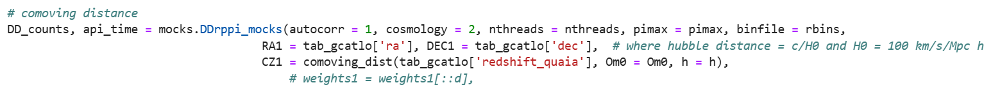

In [18]:
wp_debug = []
rpavg_debug = []
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask)
    wp_zbin_i, rpavg_zbin_i = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Omega_m_planck20, 
                                                        h = h_planck20, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax)
    wp_debug.append(wp_zbin_i)
    rpavg_debug.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0: 0.37              179640 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin3.0zmax4.0: 0.46              19252 vs 35630


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_3762/196821740.py:24: SyntaxWarning: invalid escape sequence '\l'
  second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')


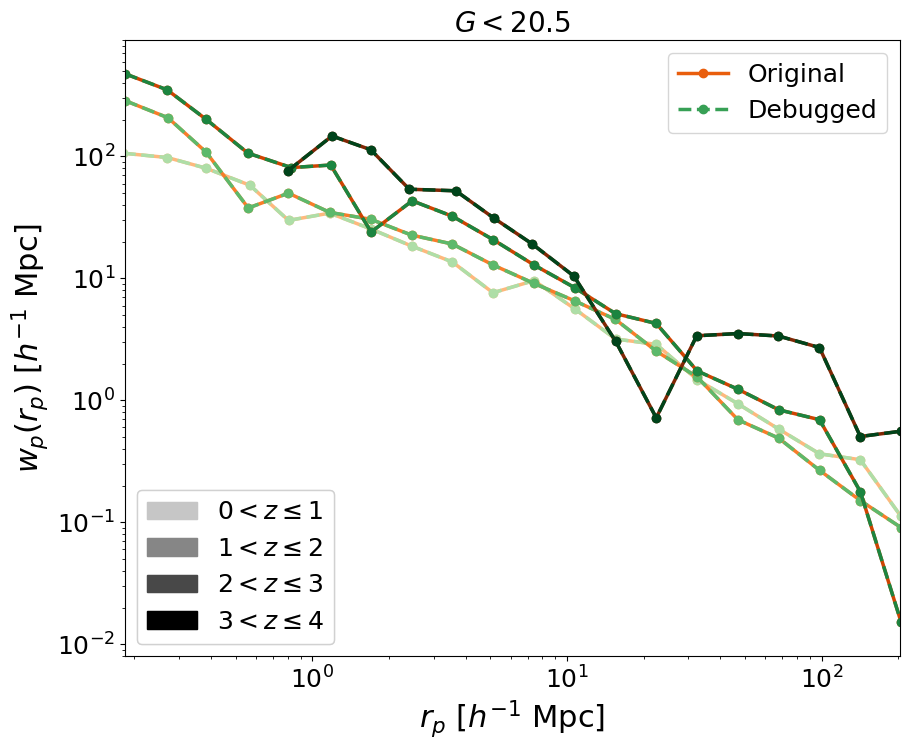

In [20]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['Original', 'Debugged']

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = r'Original', 
                 color = cmap_qq[j])
    plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = r'Debugged', linestyle = '--',
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

## Check RR counts
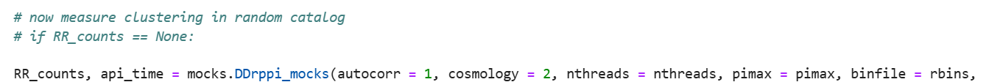

In [22]:
wp_debug = []
rpavg_debug = []
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask)
    wp_zbin_i, rpavg_zbin_i = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Omega_m_planck20, 
                                                        h = h_planck20, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax)
    wp_debug.append(wp_zbin_i)
    rpavg_debug.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0: 0.37              179640 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin3.0zmax4.0: 0.46              19252 vs 35630


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_3762/196821740.py:24: SyntaxWarning: invalid escape sequence '\l'
  second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')


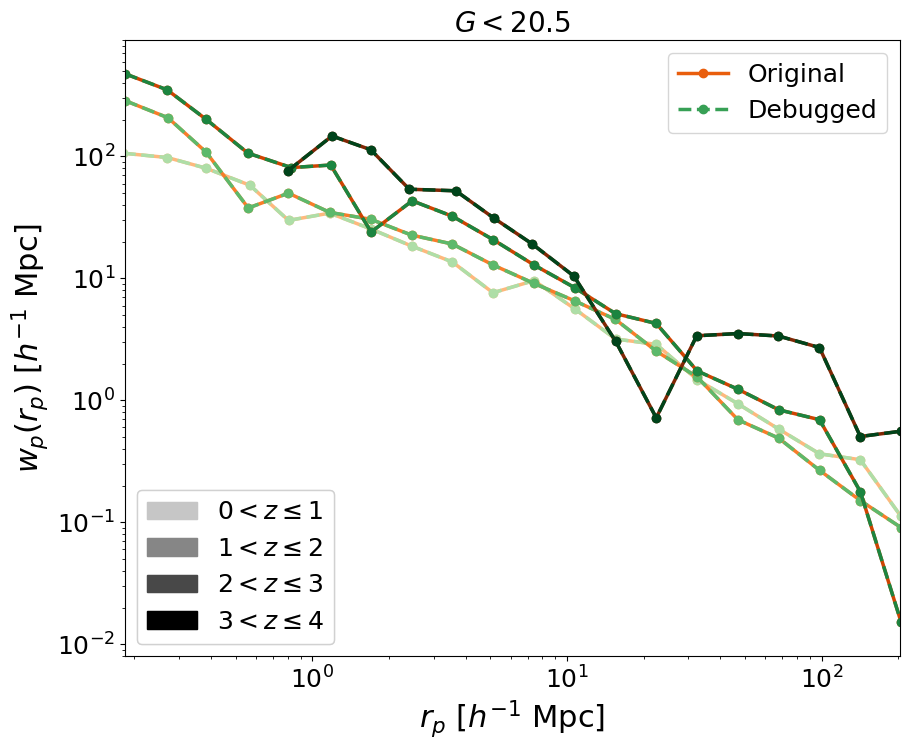

In [32]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['Original', 'Debugged']

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = r'Original', 
                 color = cmap_qq[j])
    plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = r'Debugged', linestyle = '--',
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

## Check ::d
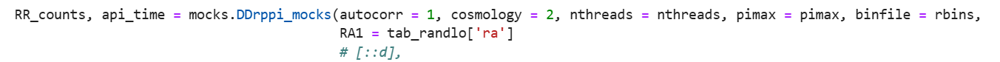

In [47]:
wp_debug = []
rpavg_debug = []
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia_debug.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask)
    wp_zbin_i, rpavg_zbin_i = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Omega_m_planck20, 
                                                        h = h_planck20, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax)
    wp_debug.append(wp_zbin_i)
    rpavg_debug.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0: 0.37              179640 vs 286508


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin3.0zmax4.0: 0.46              19252 vs 35630


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_3762/196821740.py:24: SyntaxWarning: invalid escape sequence '\l'
  second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')


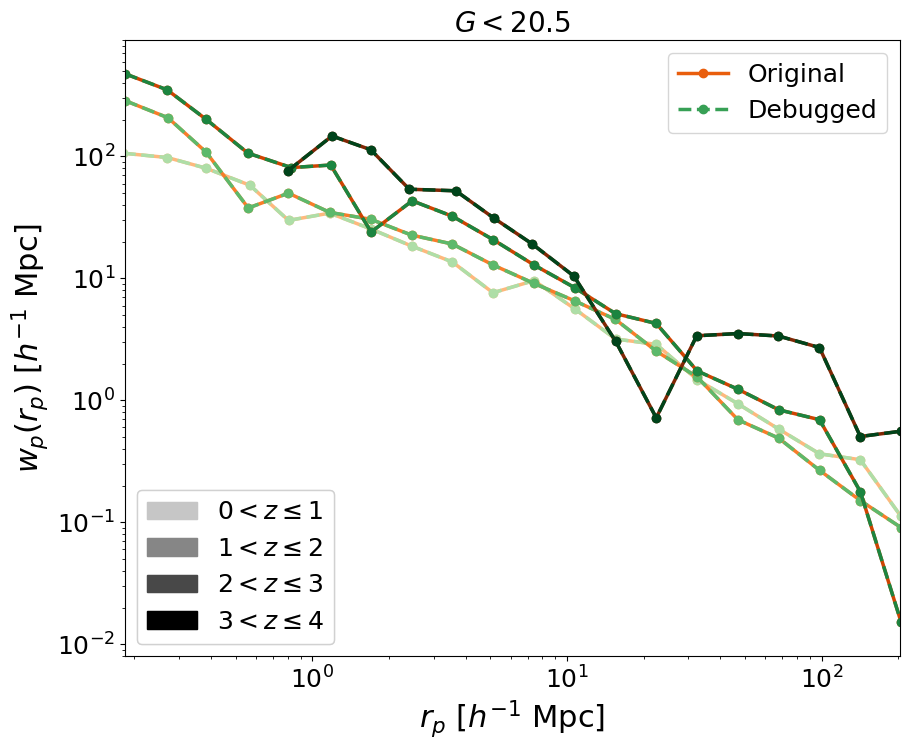

In [48]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['Original', 'Debugged']

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = r'Original', 
                 color = cmap_qq[j])
    plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = r'Debugged', linestyle = '--',
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

## Check z distribution

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


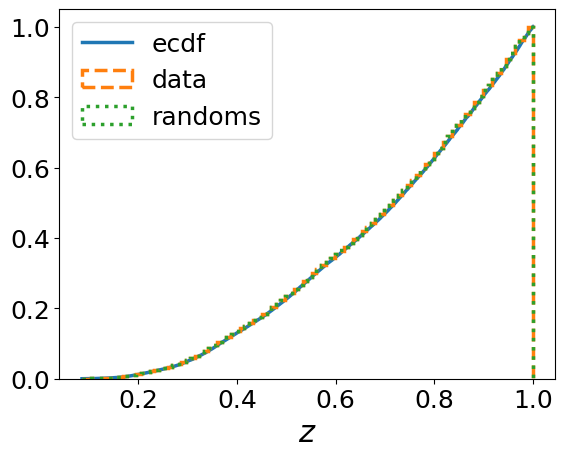

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin1.0zmax2.0: 0.17              536368 vs 648196


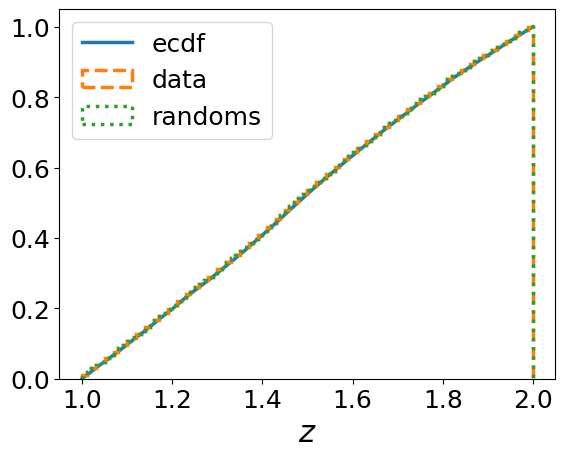

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin2.0zmax3.0: 0.37              179640 vs 286508


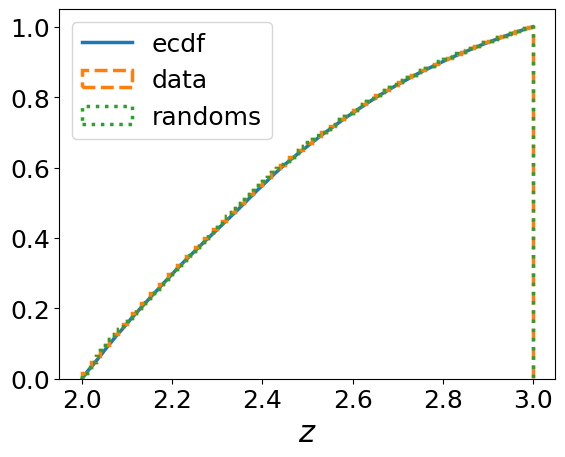

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


G20.5_zmin3.0zmax4.0: 0.46              19252 vs 35630


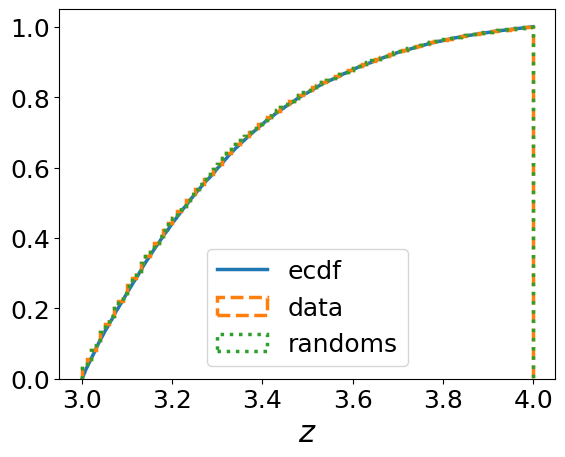

/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


In [70]:
wp_debug = []
rpavg_debug = []
    
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia_debug.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 25,
                                                                                     n_bins = [None], mask = mask, plot = True)
    wp_zbin_i, rpavg_zbin_i = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = Omega_m_planck20, 
                                                        h = h_planck20, nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax)
    wp_debug.append(wp_zbin_i)
    rpavg_debug.append(rpavg_zbin_i)

<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_3762/196821740.py:24: SyntaxWarning: invalid escape sequence '\l'
  second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')


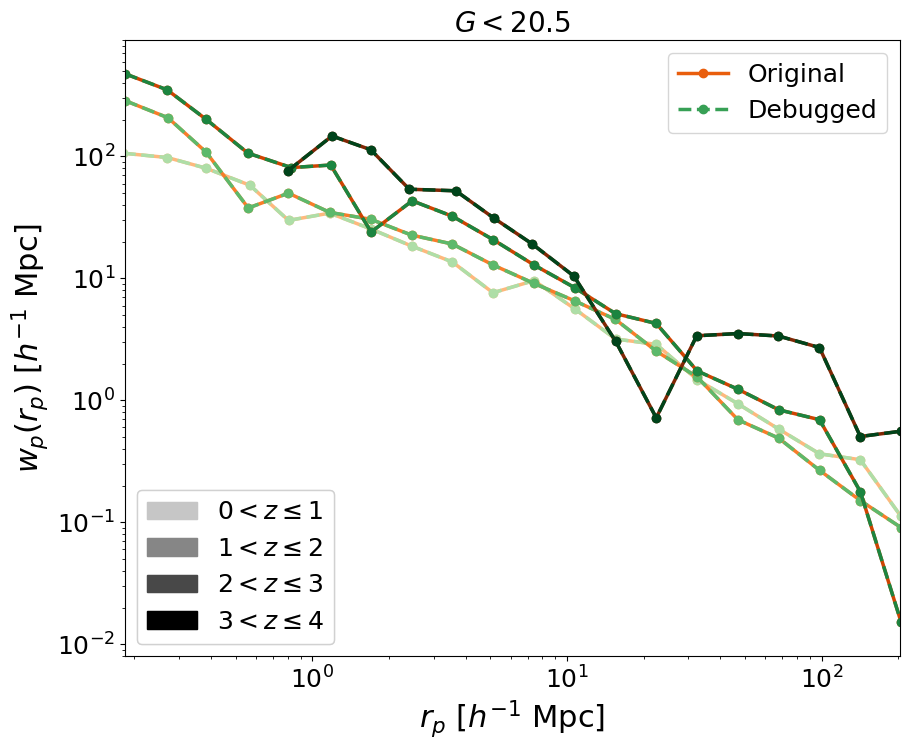

In [71]:
fig = plt.figure(figsize = (10, 8))
labels_cf = ['Original', 'Debugged']

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = r'Original', 
                 color = cmap_qq[j])
    plt.plot(rpavg_debug[j], wp_debug[j], linewidth = 2.5, marker = 'o', label = r'Debugged', linestyle = '--',
                 color = cmap_mm[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
                    Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

## Check the mask

G20.5_zmin0.0zmax1.0: 0.30              225792 vs 324336


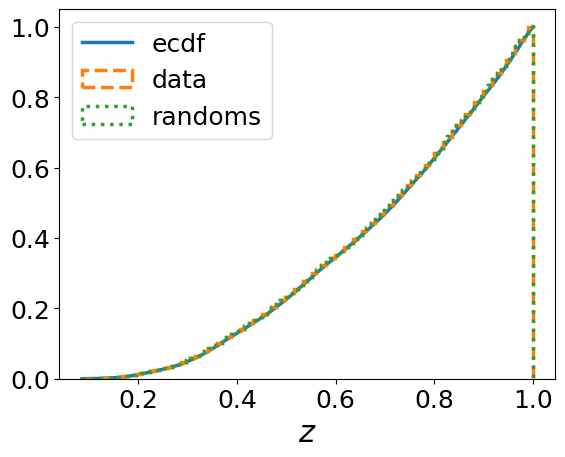

G20.5_zmin1.0zmax2.0: 0.28              467913 vs 648196


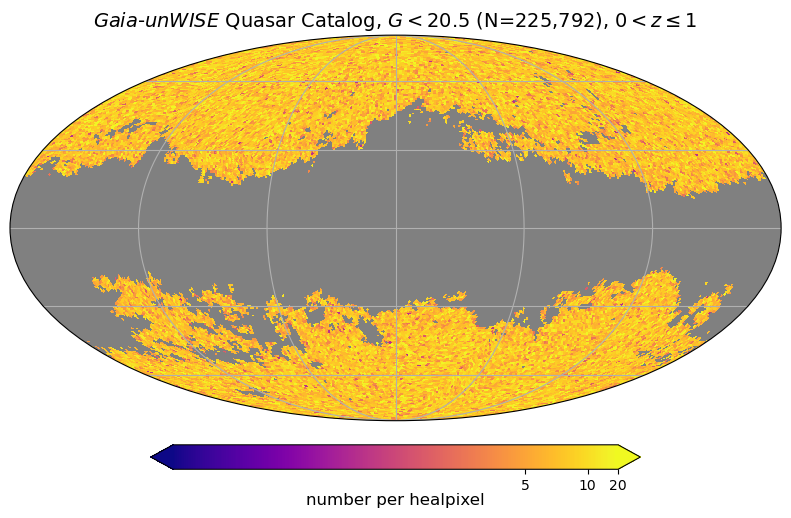

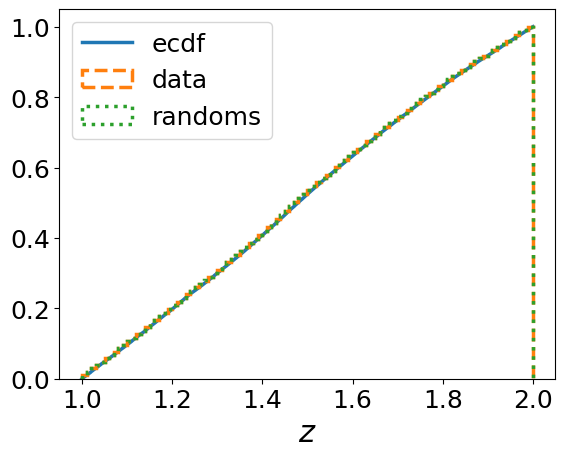

G20.5_zmin2.0zmax3.0: 0.24              216828 vs 286508


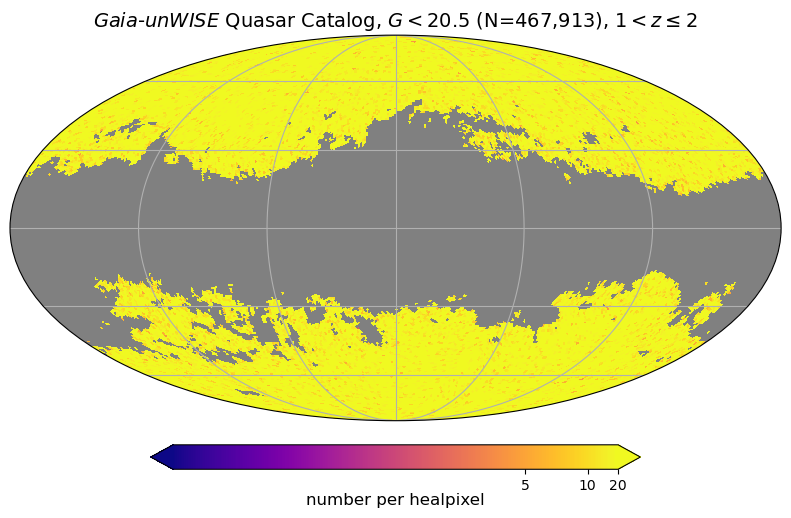

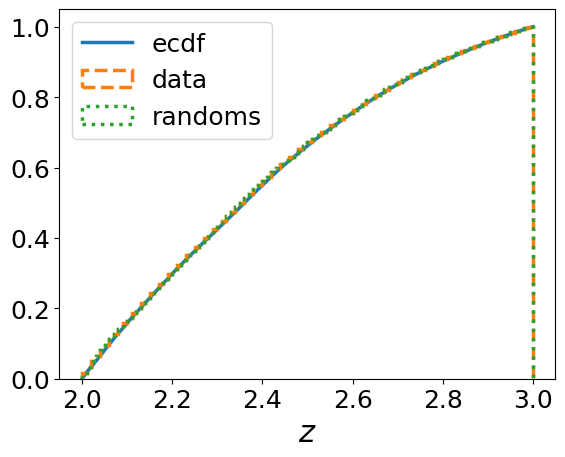

G20.5_zmin3.0zmax4.0: 0.21              28061 vs 35630


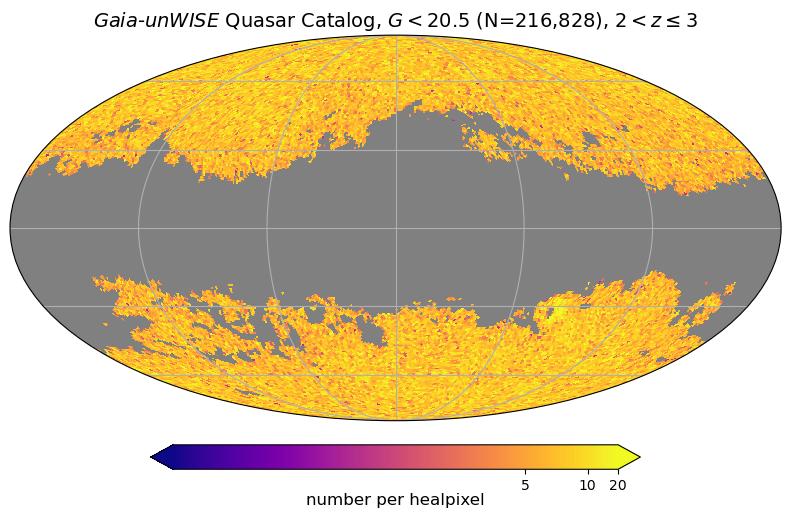

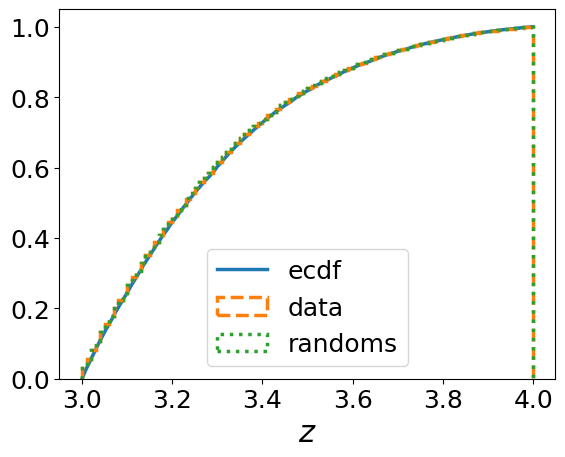

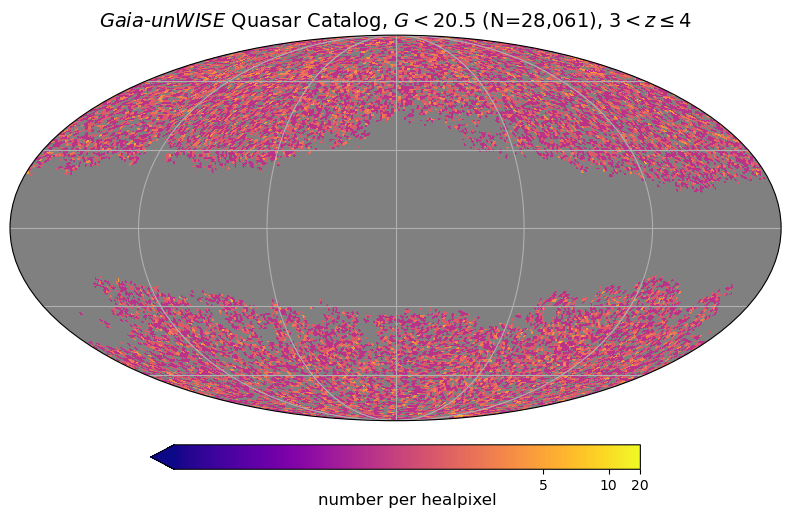

In [36]:
for j in z_array:

    #, fac_stdev = [1, 1, 0.9, 0.5][j])
    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask = mask*100, 
                                                                                               plot = True, percentile = True) 

G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336


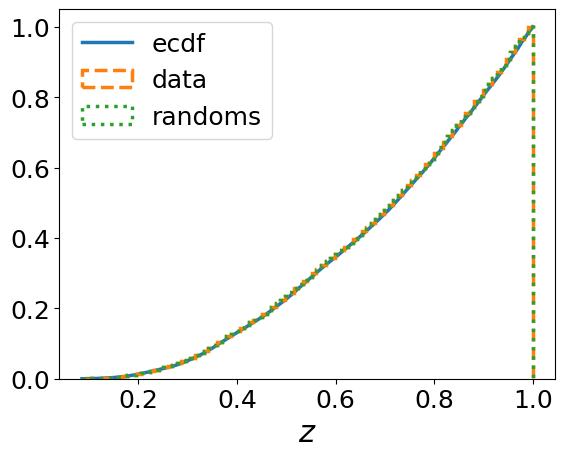

G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196


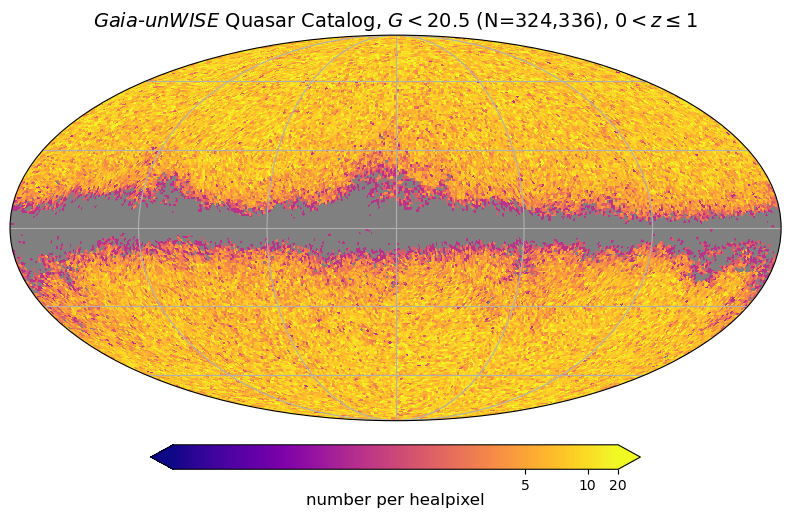

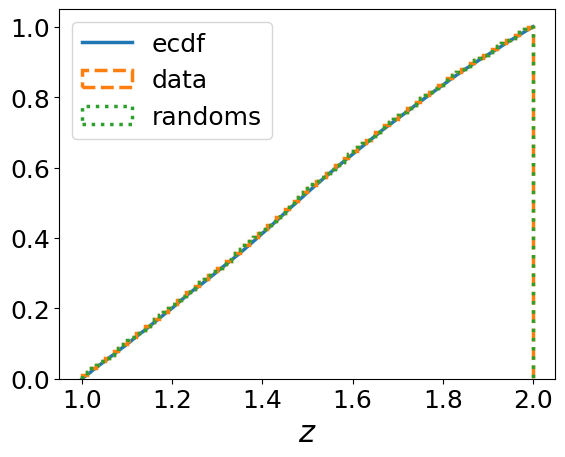

G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508


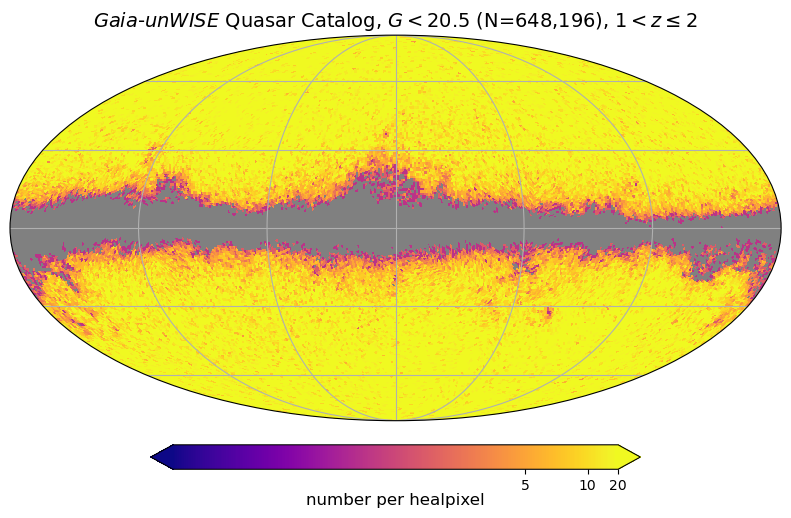

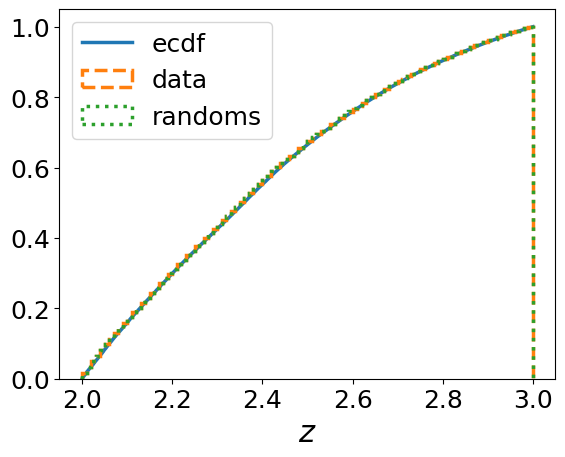

G20.5_zmin3.0zmax4.0: 0.23              27584 vs 35630


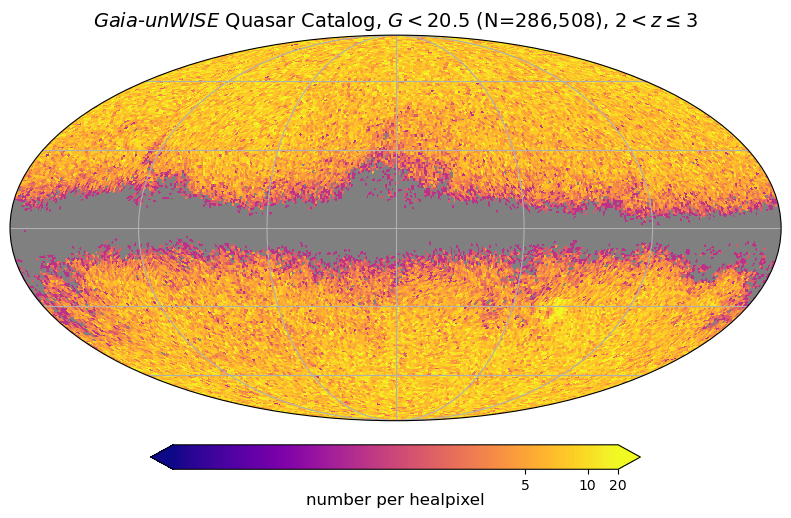

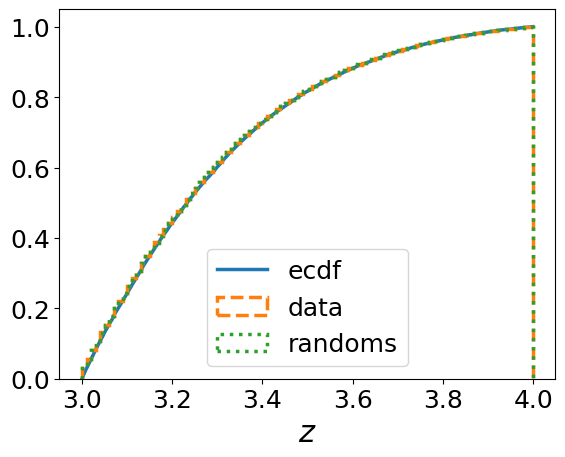

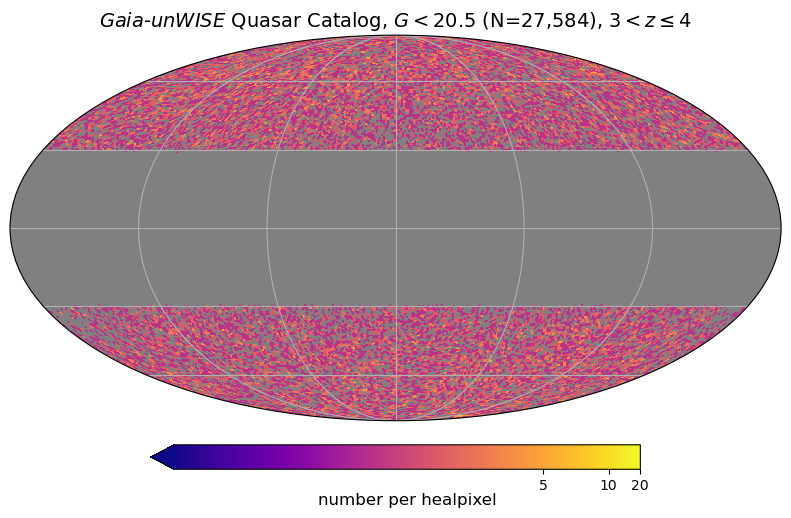

In [33]:
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                               plot = True, b = [0,0,0,30][j]) 

## Check random catalog

../data/randoms/random_G20.5_zmin0.0zmax1.0_25x.fits
G20.5_zmin0.0zmax1.0: 0.30              225792 vs 324336
24.59516723356009


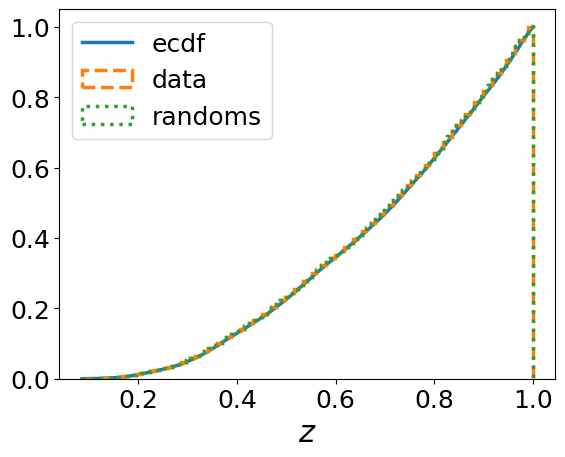

0.0
0.0
../data/randoms/random_G20.5_zmin1.0zmax2.0_25x.fits
G20.5_zmin1.0zmax2.0: 0.28              467913 vs 648196
24.769275484972635


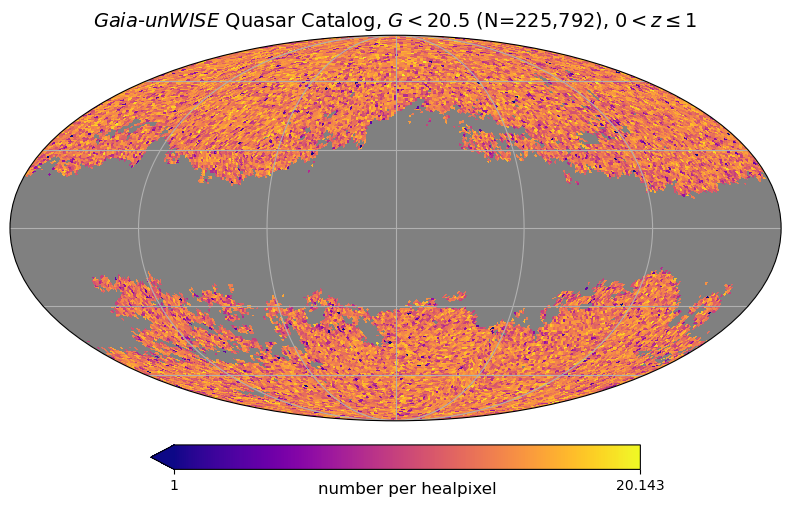

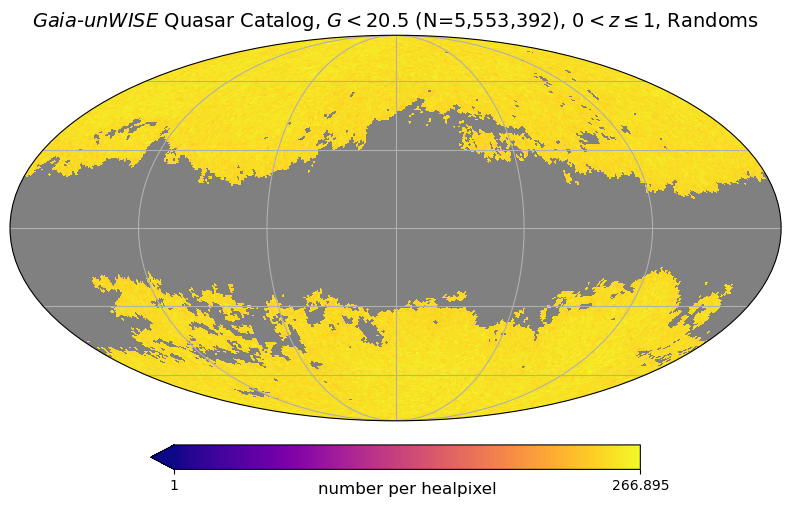

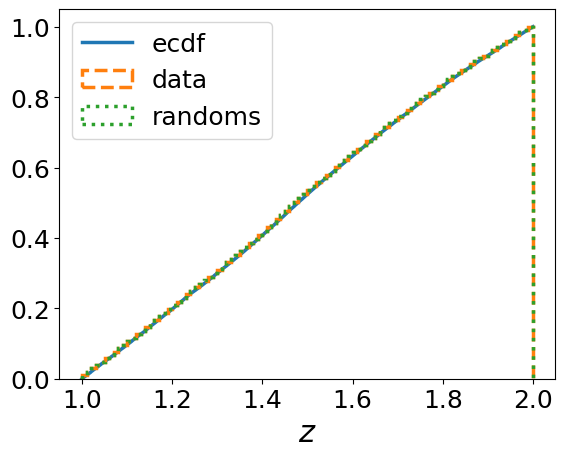

0.0
0.0
../data/randoms/random_G20.5_zmin2.0zmax3.0_25x.fits
G20.5_zmin2.0zmax3.0: 0.24              216828 vs 286508
24.316536609662958


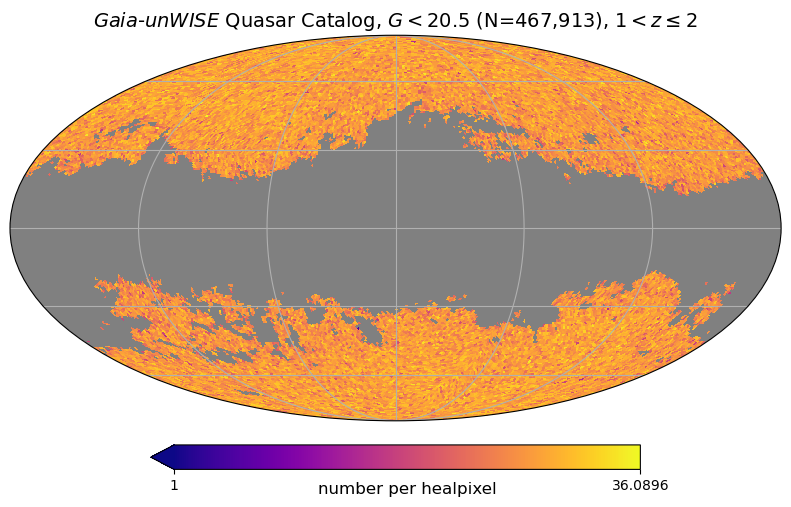

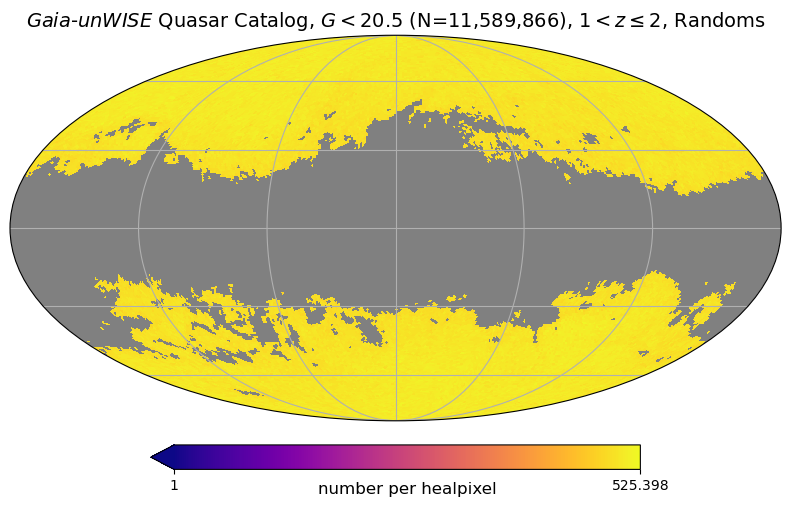

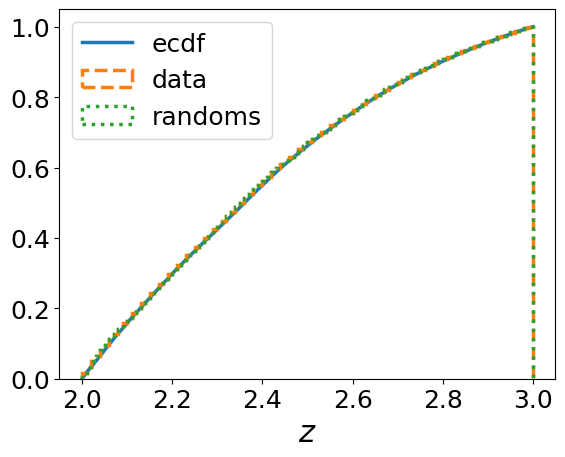

0.0
0.0
../data/randoms/random_G20.5_zmin3.0zmax4.0_25x.fits
G20.5_zmin3.0zmax4.0: 0.21              28061 vs 35630
20.88817219628666


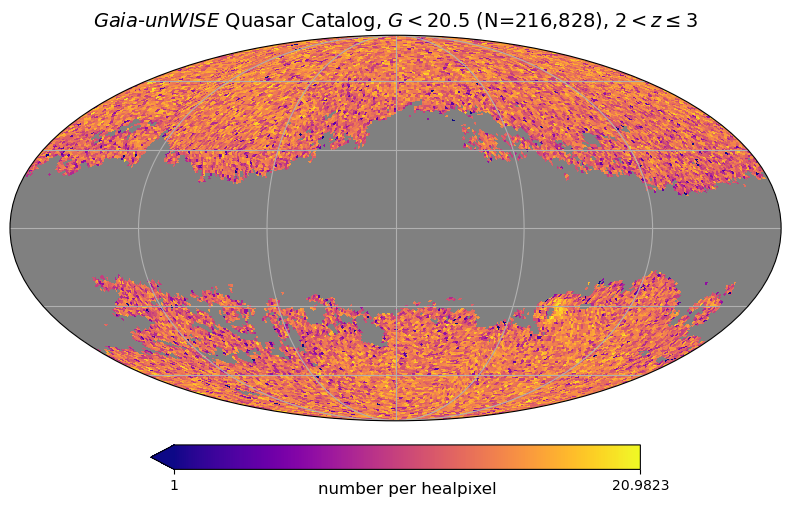

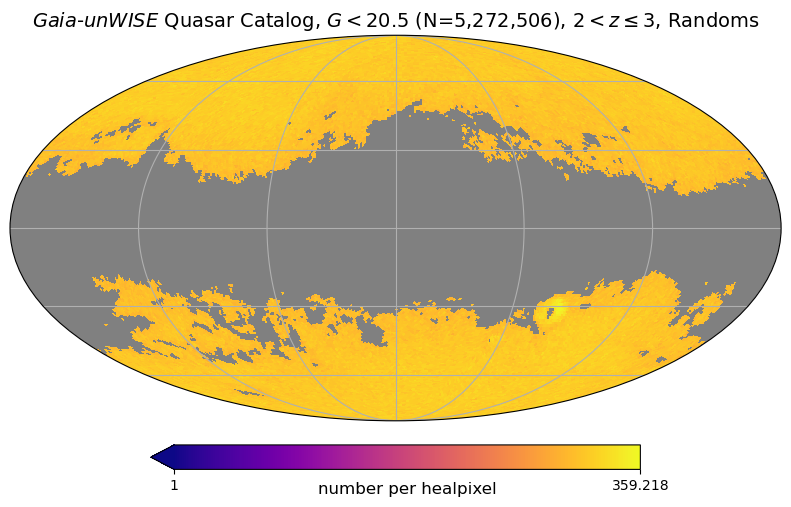

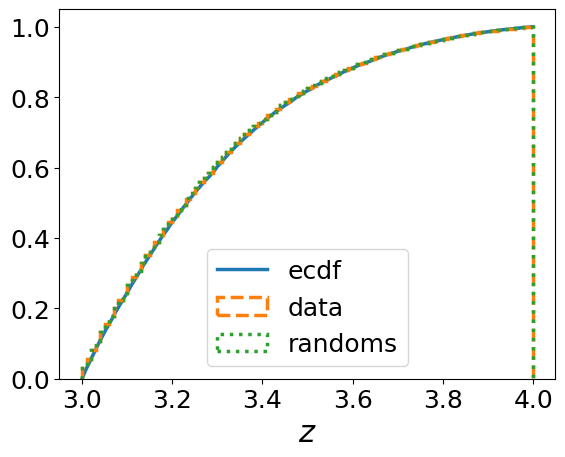

0.0
0.0


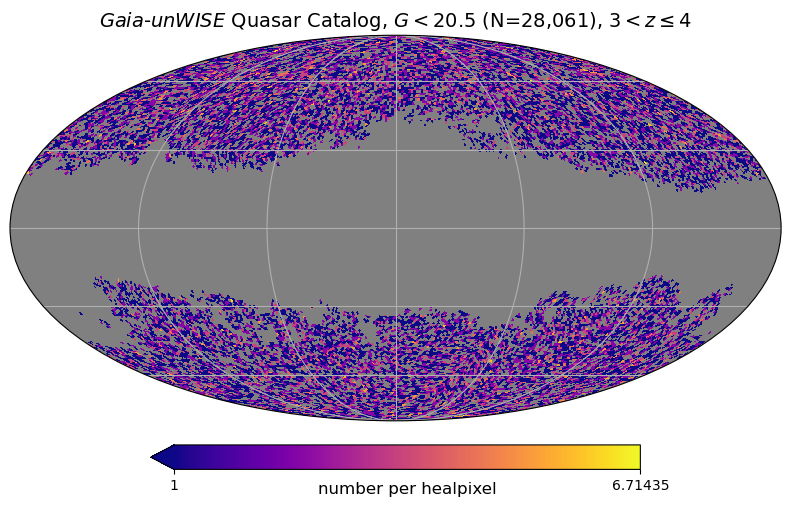

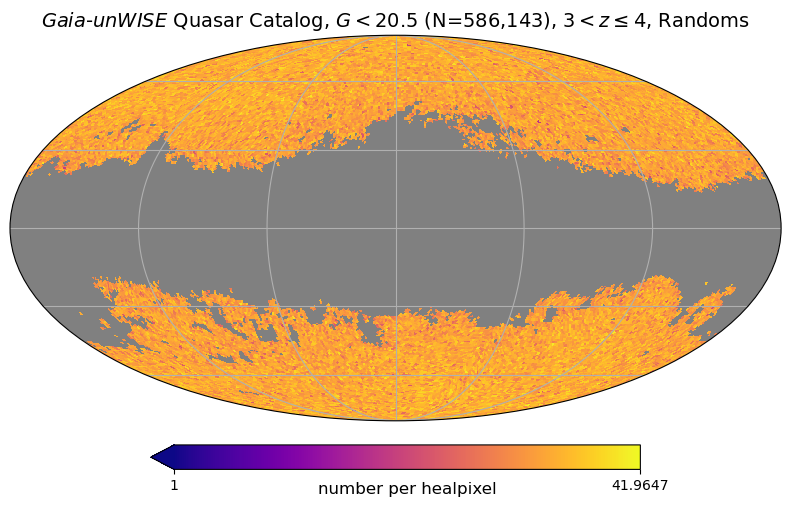

In [69]:
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _= quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask = mask*100, 
                                                                                               plot = True, percentile = True) 

../data/randoms/random_G20.5_zmin0.0zmax1.0_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.999142864190222


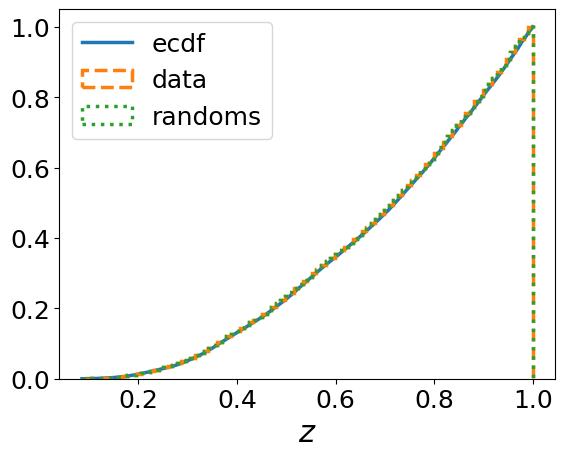

0.0
0.0
../data/randoms/random_G20.5_zmin1.0zmax2.0_25x.fits
G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196
24.99197464964301


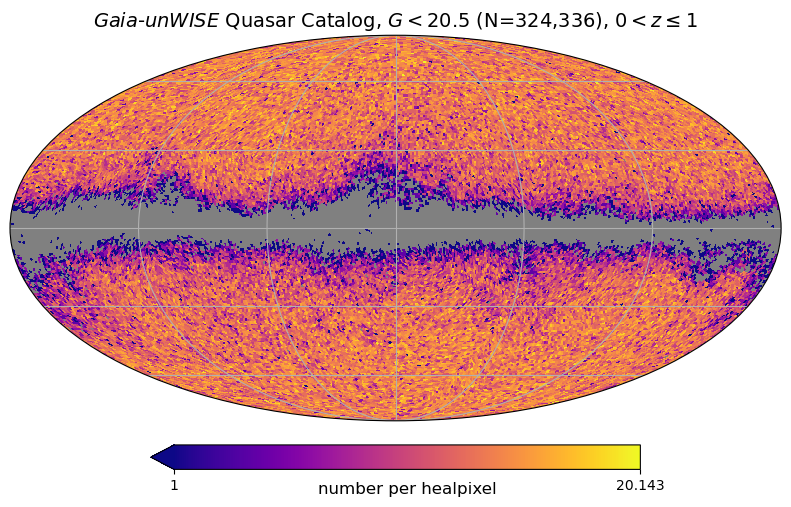

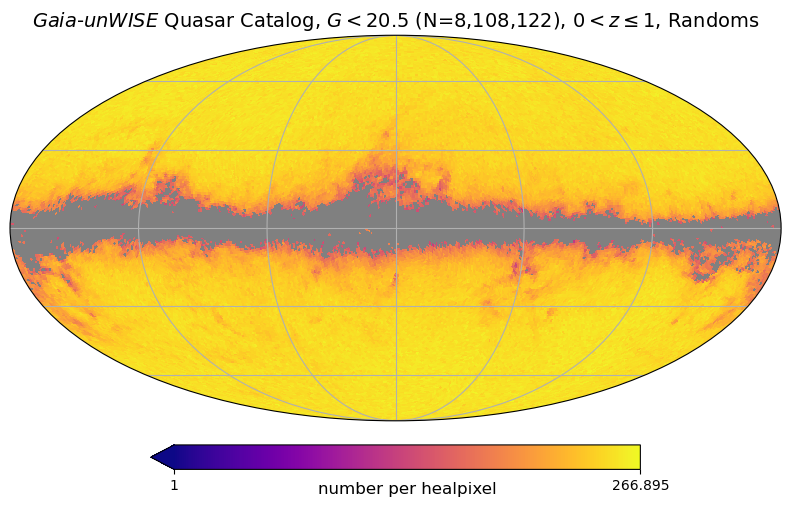

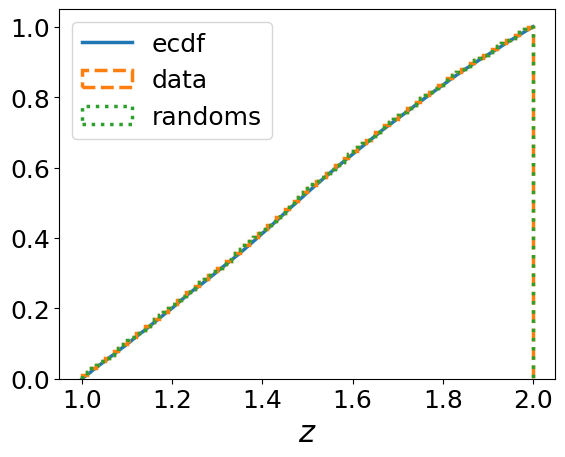

0.0
0.0
../data/randoms/random_G20.5_zmin2.0zmax3.0_25x.fits
G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508
24.969278344758262


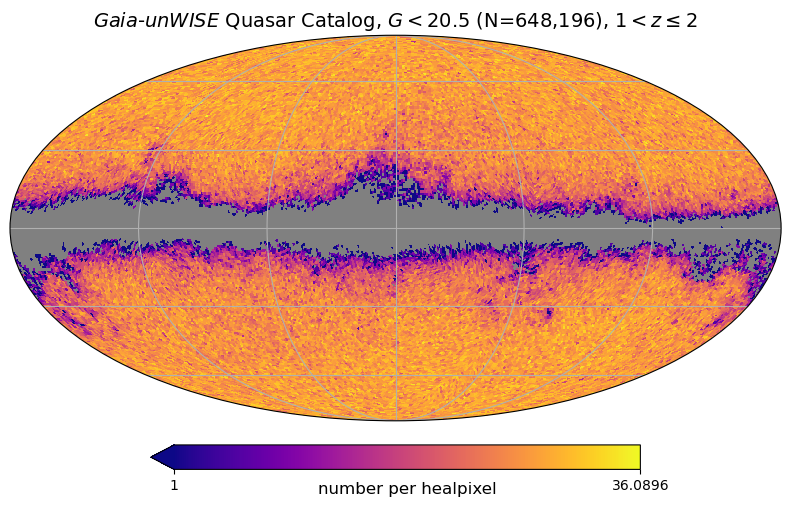

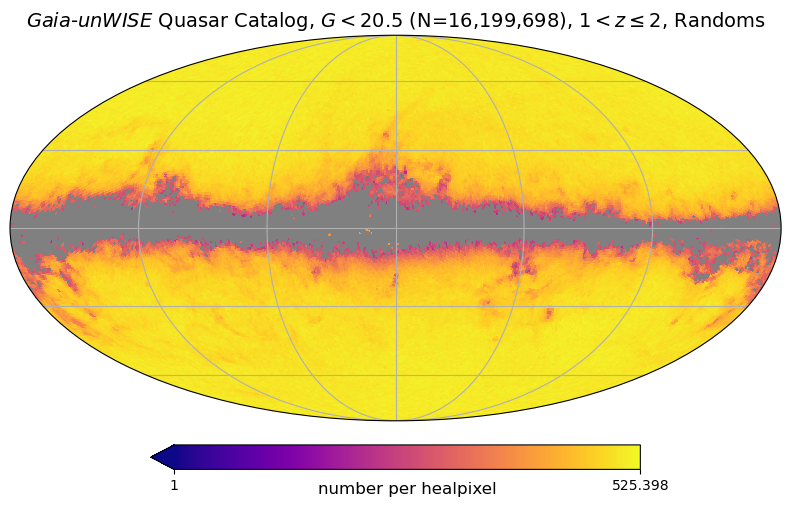

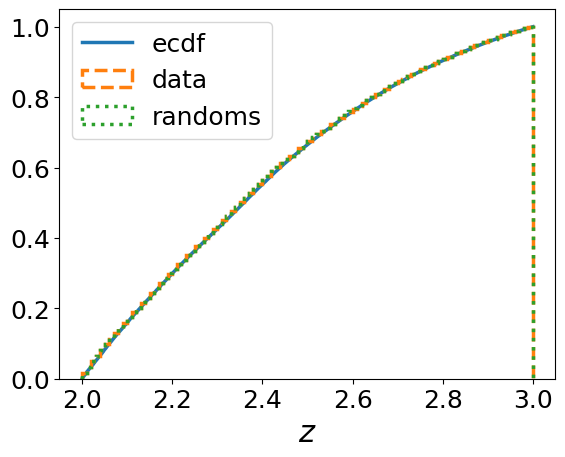

0.0
0.0
../data/randoms/random_G20.5_zmin3.0zmax4.0_25x.fits
G20.5_zmin3.0zmax4.0: 0.23              27584 vs 35630
20.923035092807424


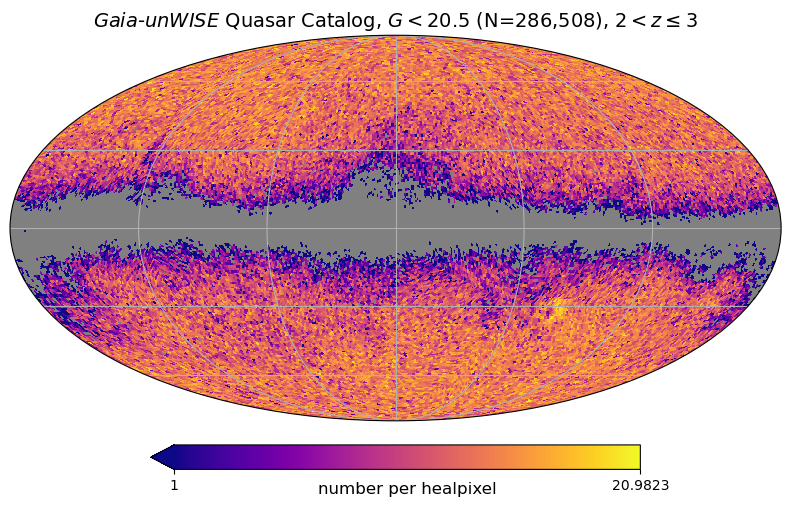

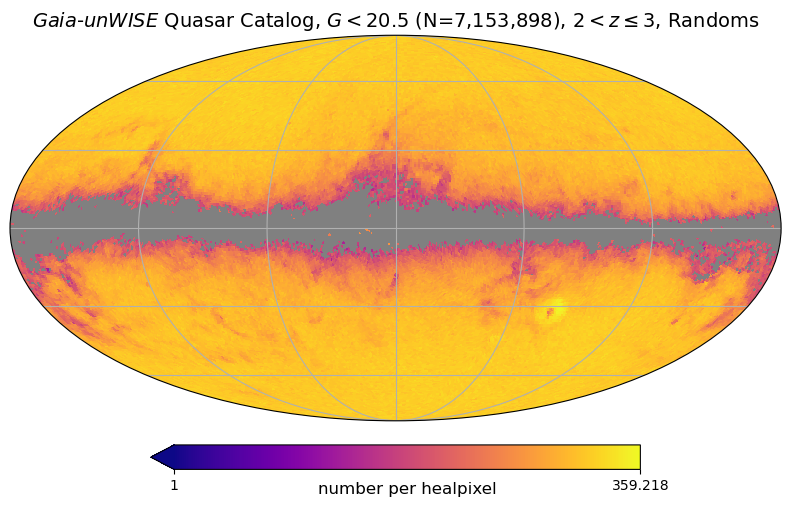

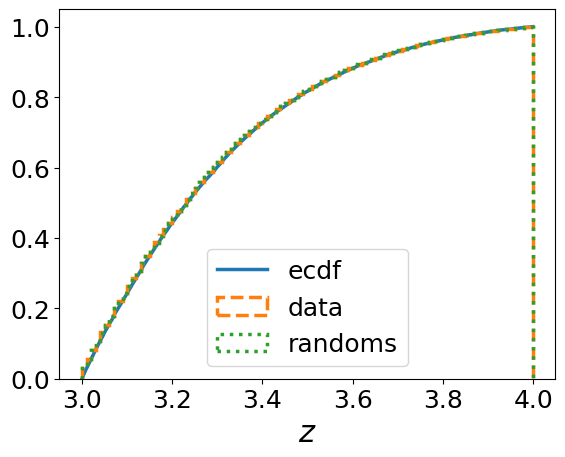

0.0
0.0


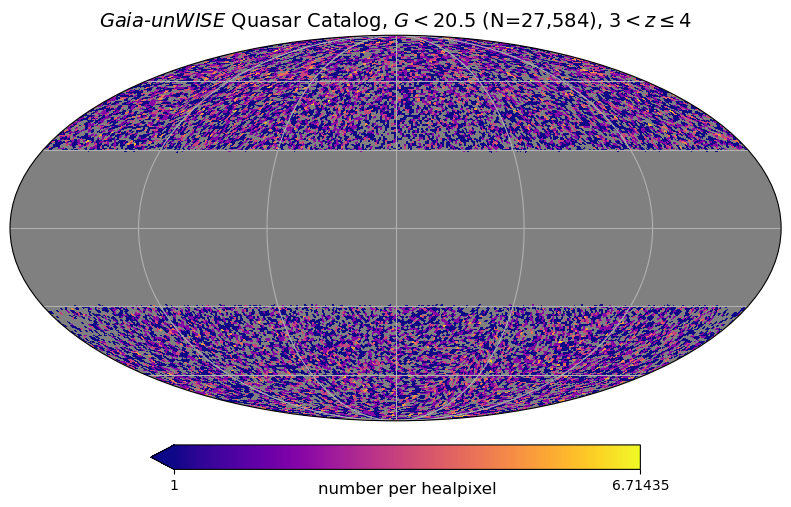

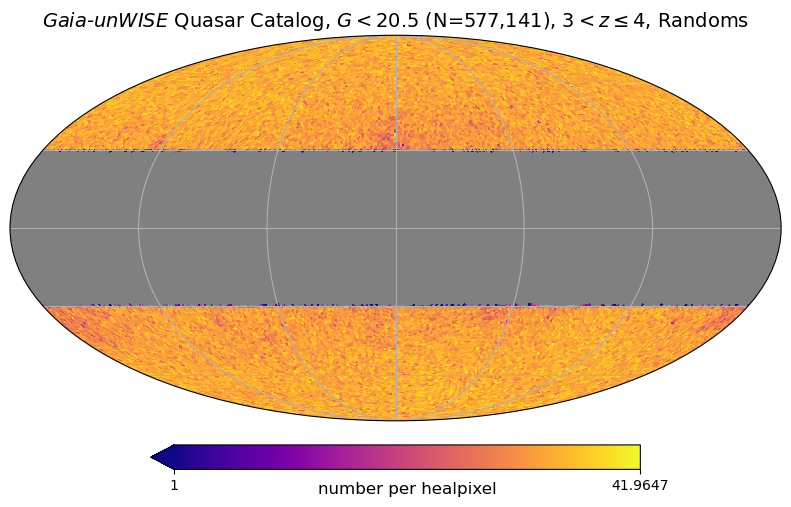

In [70]:
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, _, _ = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                               plot = True, b = [0,0,0,30][j]) 

### Check that the randoms follow the data

In [71]:
importlib.reload(quaia_debug)

<module 'quaia_debug' from '/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia_debug.py'>

In [119]:
NSIDE = 64
NPIX = hp.nside2npix(NSIDE)

../data/randoms/random_G20.5_zmin0.0zmax1.0_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.999142864190222


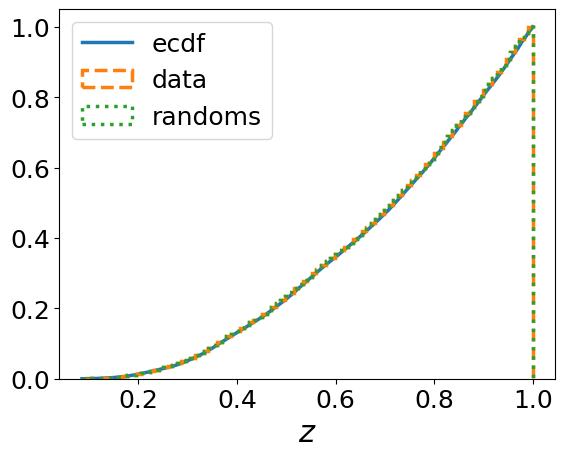

0.0
0.0


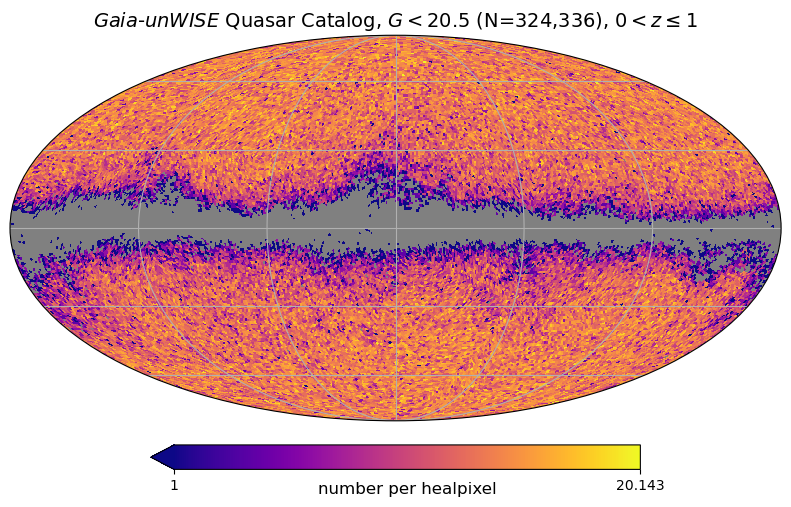

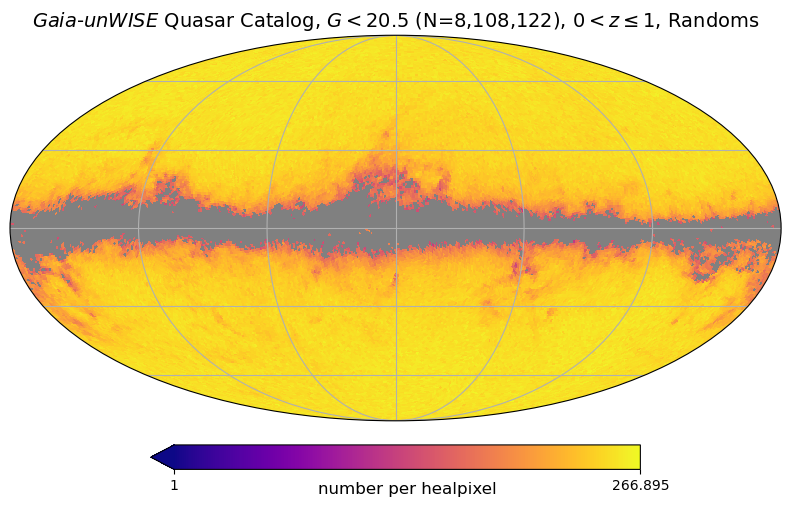

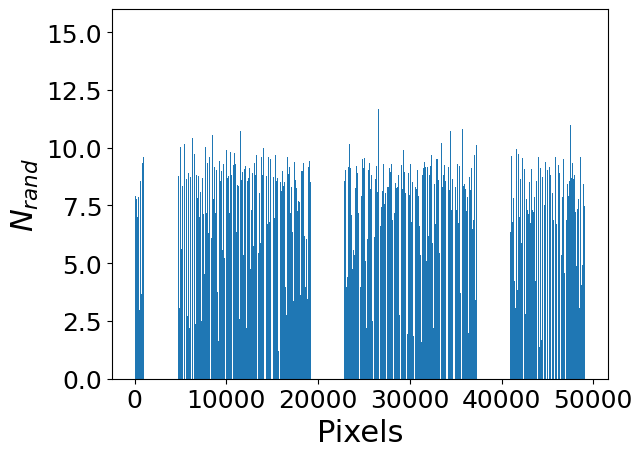

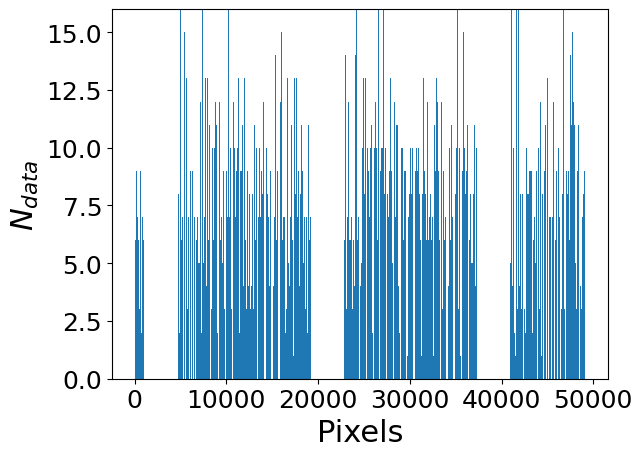

../data/randoms/random_G20.5_zmin1.0zmax2.0_25x.fits
G20.5_zmin1.0zmax2.0: 0.00              648196 vs 648196
24.99197464964301


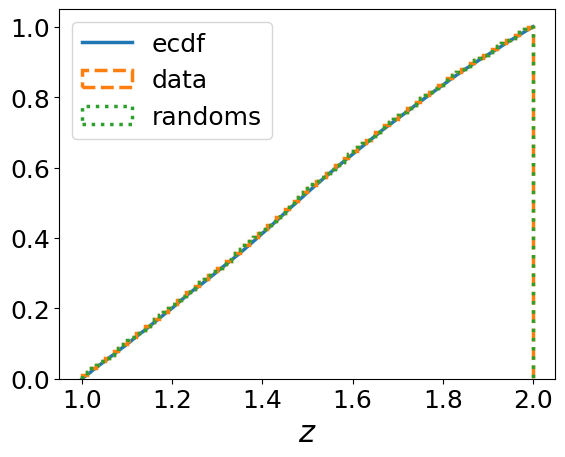

0.0
0.0


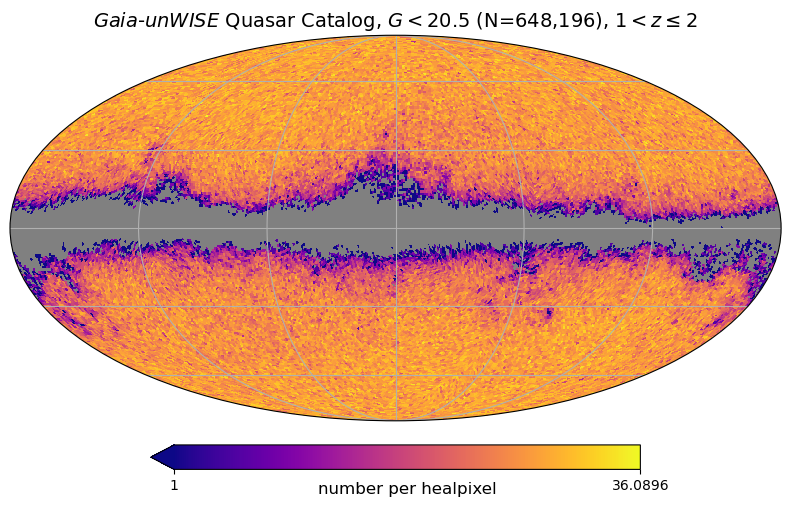

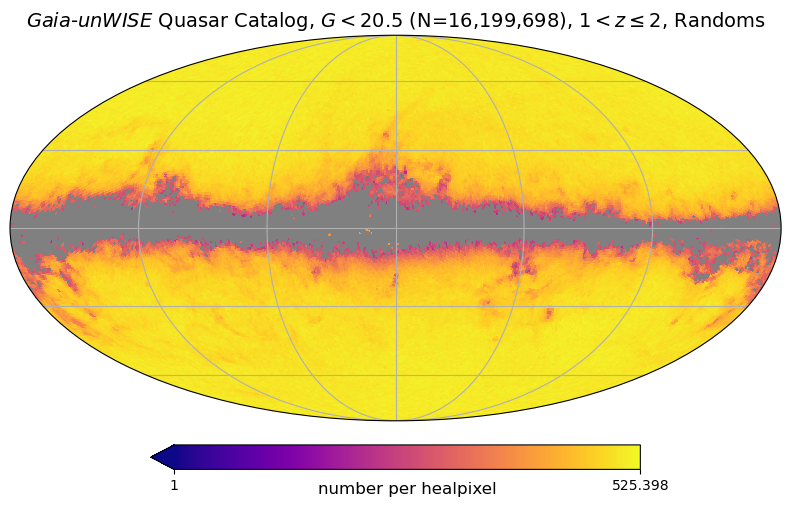

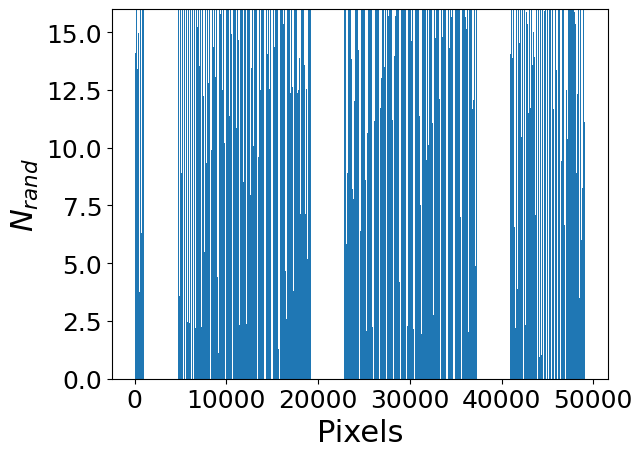

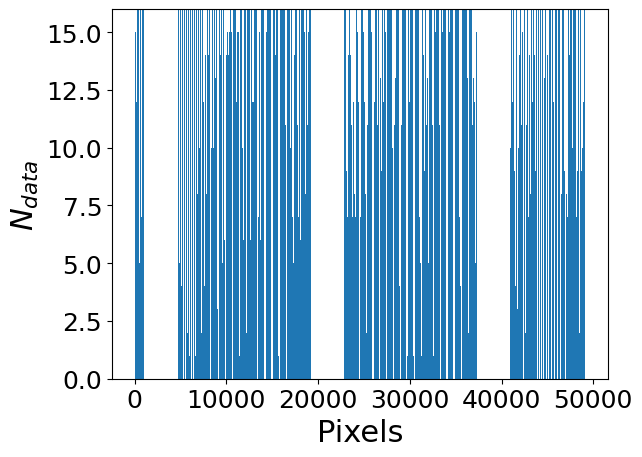

../data/randoms/random_G20.5_zmin2.0zmax3.0_25x.fits
G20.5_zmin2.0zmax3.0: 0.00              286508 vs 286508
24.969278344758262


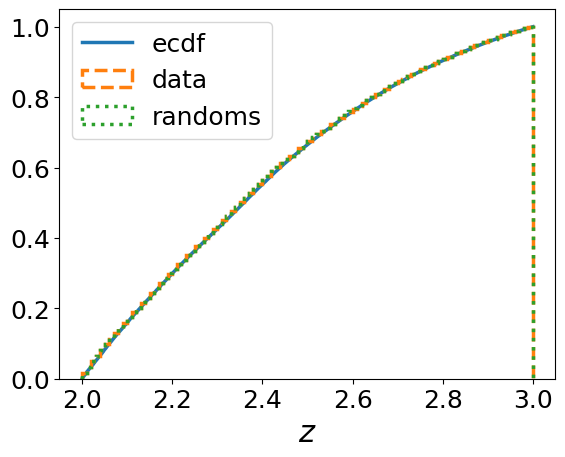

0.0
0.0


In [ ]:
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, map_gcatlo, map_randlo = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                                   tab_gcat_type = 'data', method = ['minmax'], 
                                                                                                   fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                                   plot = True, b = [0,0,0,30][j])
    # wp_debug, rpavg_debug, qq, qr = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0,
    #                                                   nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)

    plt.figure()
    plt.bar(np.arange(NPIX), map_randlo/25, label = 'randoms')
    plt.xlabel('Pixels')
    plt.ylabel('$N_{rand}$')
    plt.ylim(0, 16)
    plt.show()

    plt.bar(np.arange(NPIX), map_gcatlo, label = 'data')
    plt.xlabel('Pixels')
    plt.ylabel('$N_{data}$')
    plt.ylim(0, 20)
    plt.show()

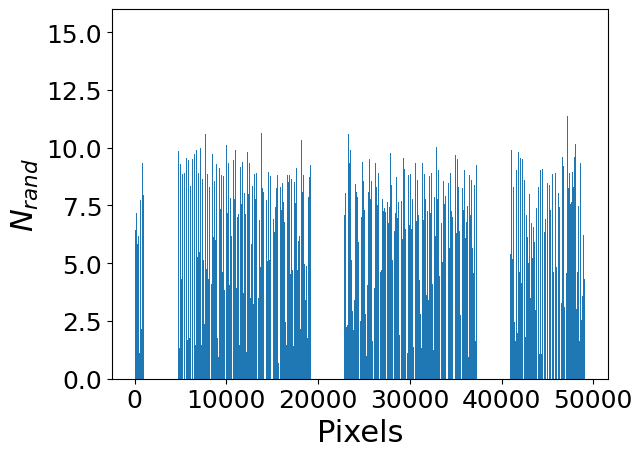

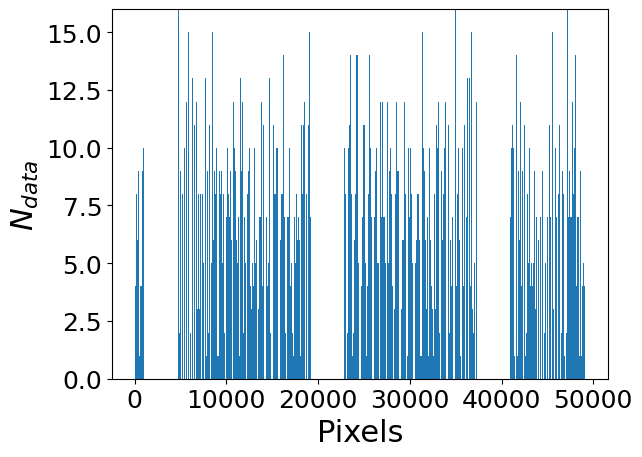

In [120]:
plt.bar(np.arange(NPIX), map_randlo/25, label = 'randoms')
plt.xlabel('Pixels')
plt.ylabel('$N_{rand}$')
plt.ylim(0, 16)
plt.show()

plt.bar(np.arange(NPIX), map_gcatlo, label = 'data')
plt.xlabel('Pixels')
plt.ylabel('$N_{data}$')
plt.ylim(0, 16)
plt.show()

../data/randoms/random_G20.5_zmin0.0zmax1.0_p_rand_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.999142864190222


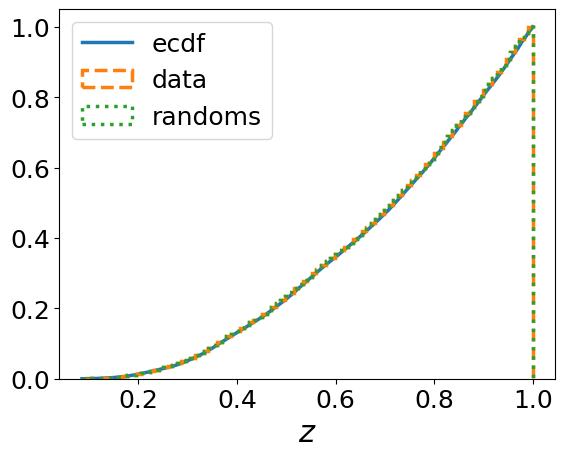

0.0
0.0


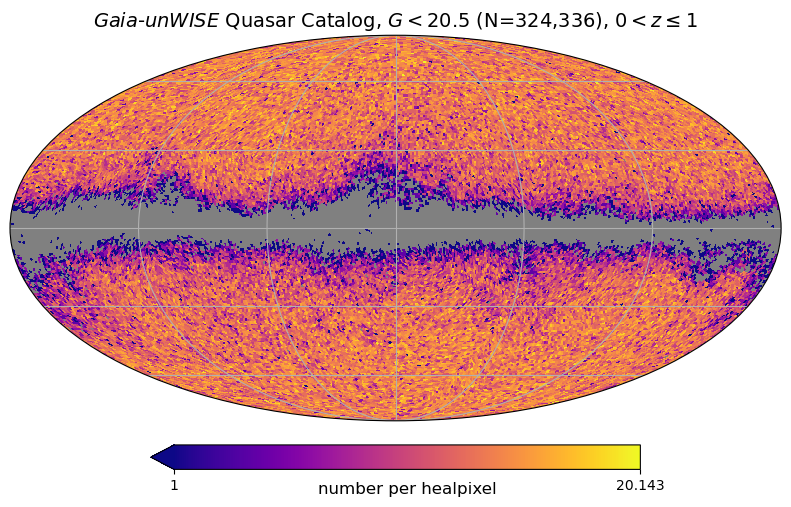

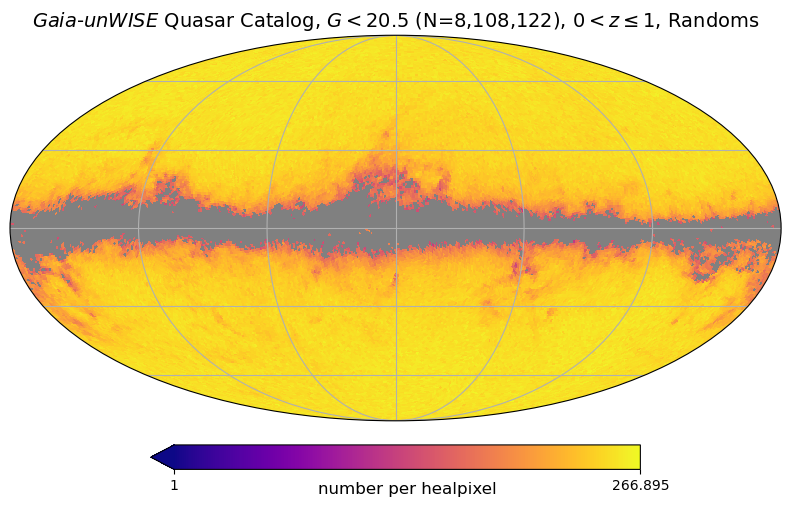

In [121]:
j = 0
tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, map_gcatlo, map_randlo = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                               plot = True, b = [0,0,0,30][j], allsky = '_p_rand')

../data/randoms/random_G20.5_zmin0.0zmax1.0_map_p_25x.fits
G20.5_zmin0.0zmax1.0: 0.00              324336 vs 324336
24.999142864190222


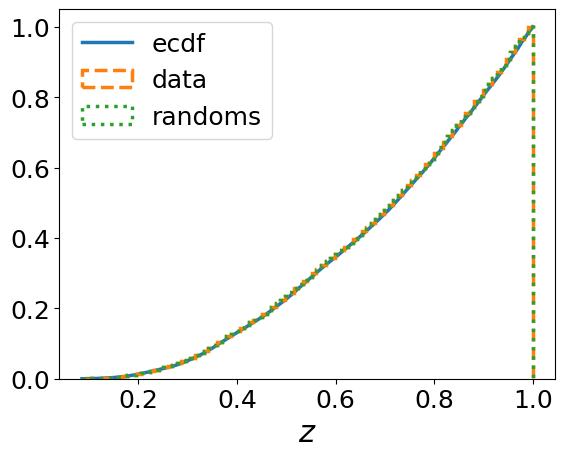

0.0
0.0


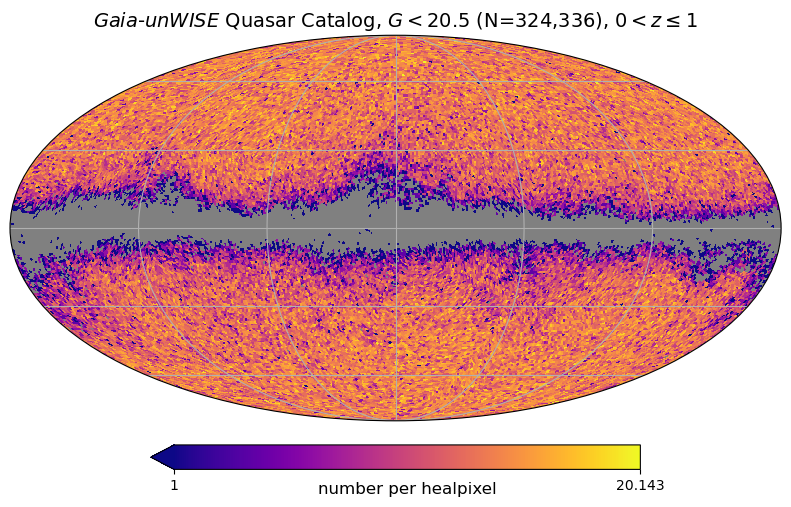

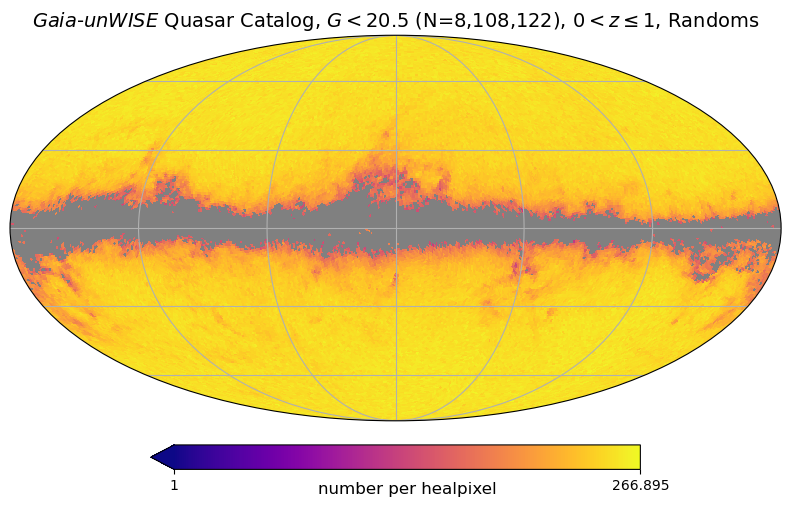

In [122]:
tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _, map_gcatlo_map_p, map_randlo_map_p = quaia_debug.make_bins(G_hi, [j], True, ['z'], bins = [z_bins],
                                                                                               tab_gcat_type = 'data', method = ['minmax'], 
                                                                                               fac_rand = 25, n_bins = [None], mask_type = 'b',
                                                                                               plot = True, b = [0,0,0,30][j], allsky = '_map_p')

## Check custom cosmology
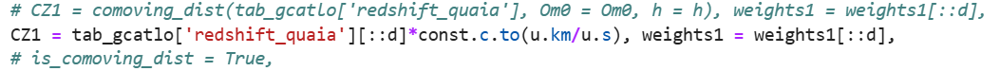

In [32]:
# wp_zbin_percentile = []
# rpavg_zbin_percentile = []
j = 0
# for j in z_array:

tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                 bins = [z_bins], tab_gcat_type = 'data',
                                                                                 method = ['minmax'], fac_rand = 25,
                                                                                 n_bins = [None], mask = mask)
wp_zbin_percentile, rpavg_zbin_percentile, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0,
                                                  nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
# wp_zbin_percentile.append(wp_zbin_i)
# rpavg_zbin_percentile.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


In [33]:
d = 1
tab_datahi_mask_zbin0['redshift_quaia'][::d]*const.c.to(u.km/u.s)*h_planck20/cu.littleh

<Quantity [ 84232.16814149, 166020.32797076, 162351.22026599, ...,
           101658.71651975, 184396.6622904 ,  88412.31503604] km / (littleh s)>

In [34]:
importlib.reload(quaia_debug)

<module 'quaia_debug' from '/oak/stanford/orgs/kipac/users/mahlet/quaia_bias/scripts/quaia_debug.py'>

In [44]:
# wp_debug = []
# rpavg_debug = []
    
# for j in z_array:

tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                 bins = [z_bins], tab_gcat_type = 'data',
                                                                                 method = ['minmax'], fac_rand = 25,
                                                                                 n_bins = [None], mask = mask)
wp_debug, rpavg_debug, qq, qr = quaia_debug.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0,
                                                  nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
# wp_debug.append(wp_zbin_i)
# rpavg_debug.append(rpavg_zbin_i)

G20.5_zmin0.0zmax1.0: 0.22              253398 vs 324336


/home/groups/tabel/mahlet/pyccl-env/lib/python3.12/site-packages/Corrfunc/utils.py:918: UserWarning: One or more input array has non-native endianness!  A copy will be made with the correct endianness.
  warnings.warn("One or more input array has non-native endianness!  A copy will"\


In [35]:
galaxy_catalog=pjoin(dirname(abspath(Corrfunc.__file__)),
                     "../mocks/tests/data", "Mr19_mock_northonly.rdcz.ff")

# Read the supplied galaxies on a periodic box
RA, DEC, CZ = read_catalog(galaxy_catalog)
N = len(RA)

# Read the supplied randoms catalog
random_catalog=pjoin(dirname(abspath(Corrfunc.__file__)),
                     "../mocks/tests/data", "Mr19_randoms_northonly.rdcz.ff")
rand_RA, rand_DEC, rand_CZ = read_catalog(random_catalog)
rand_N = len(rand_RA)

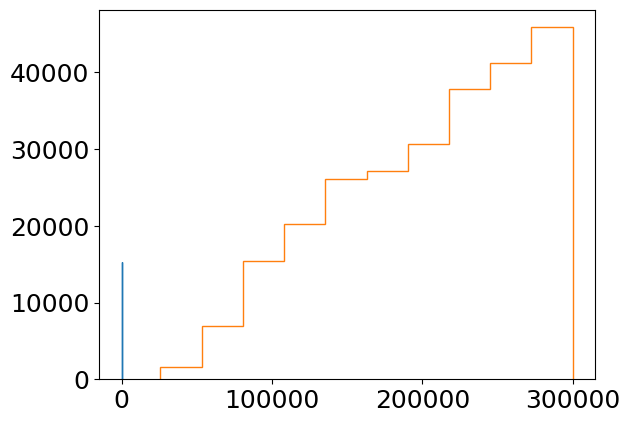

In [51]:
plt.hist(CZ/H0_planck20.value, histtype = 'step')
plt.hist(tab_datahi_mask_zbin0['redshift_quaia']*const.c.to(u.km/u.s).value, histtype = 'step')
plt.show()

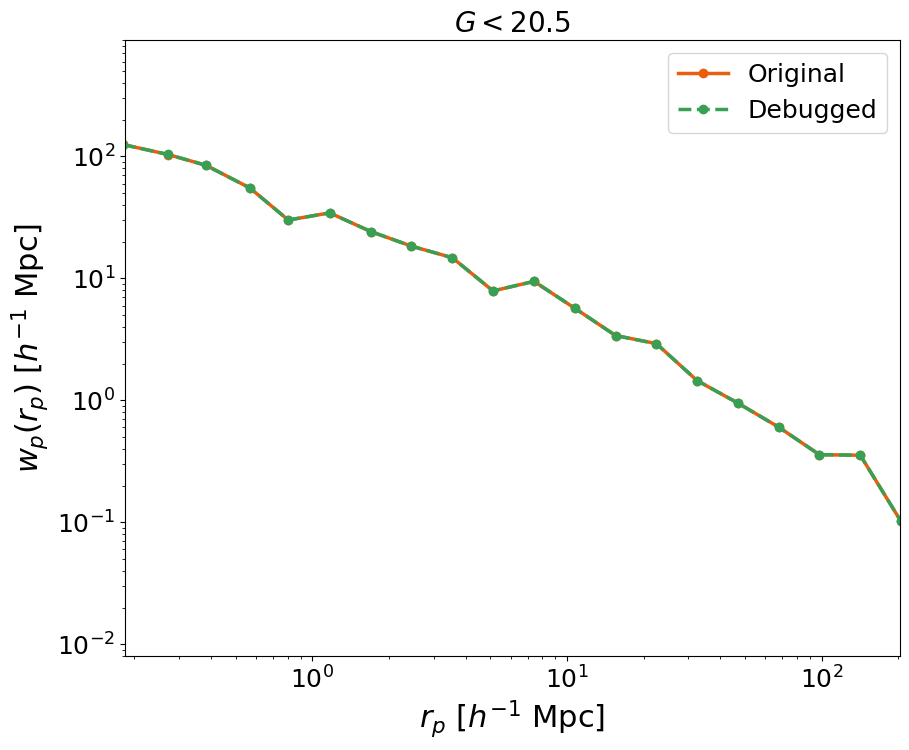

In [46]:
fig = plt.figure(figsize = (10, 8))

labels_cf = ['Original', 'Debugged']

# for j in z_array:

plt.plot(rpavg_zbin_percentile, wp_zbin_percentile, linewidth = 2.5, marker = 'o', label = r'Original', 
             color = orange)
plt.plot(rpavg_debug, wp_debug, linewidth = 2.5, marker = 'o', label = r'Debugged', linestyle = '--',
             color = green)

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)
plt.legend()

# custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
#                     Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
# second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
# fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

# custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
# second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
# fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')

if scale == 'log':
    plt.xscale('log')

plt.show()

## Try plotting comparison to Mariona...

In [ ]:
# Create the bins array
rmin = 1 # 30 #0.1
rmax = 200 # 80 #180.0
nbins = 14 # 20 
rpbins = np.logspace(np.log10(rmin), np.log10(rmax), nbins + 1) # Mpc/h https://github.com/manodeep/Corrfunc/issues/202
scale = 'log' # 'linear'

In [ ]:
pimax = 100 # 80 # 40 # 5000.0 # 40.0

In [ ]:
wp_zbin_percentile = []
rpavg_zbin_percentile = []
b = [0, 0, 0, 30]
for j in z_array:

    tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, _, _, _, _= quaia.make_bins(G_hi, [j], True, ['z'], 
                                                                                     bins = [z_bins], tab_gcat_type = 'data',
                                                                                     method = ['minmax'], fac_rand = 100,
                                                                                     n_bins = [None], mask_type = 'b', b = b[j])
    wp_zbin_i, rpavg_zbin_i, qq, qr = quaia.wp_rp(tab_datahi_mask_zbin0, tab_randhi_mask_zbin0, key_zbin0, Om0 = 0.315, h = 0.674,
                                                      nthreads = nthreads, rbins = rpbins, nbins = nbins, pimax = pimax, error = True)
    wp_zbin_percentile.append(wp_zbin_i)
    rpavg_zbin_percentile.append(rpavg_zbin_i)

In [ ]:
fig = plt.figure(figsize = (10, 8))

for j in z_array:

    plt.plot(rpavg_zbin_percentile[j], wp_zbin_percentile[j], linewidth = 2.5, marker = 'o', label = '${:.0f}<z \leq{:.0f}$'.format(j, j+1), 
                 color = cmap_qq[j])

plt.title('$G<{}$'.format(G_hi))
plt.yscale('log')
plt.ylim(8e-3, 9e2)

# custom_lines = [Line2D([0], [0], color = orange, marker = 'o', linestyle = '-', linewidth = 2.5), 
#                     Line2D([0], [0], color = green, marker = 'o', linestyle = '--', linewidth = 2.5)]
# second_legend = plt.legend(custom_lines, labels_cf, loc = 'upper right')
# fig.add_artist(second_legend)
    
plt.xlabel(r'$r_p$ $[h^{-1}$ Mpc]') # projected
plt.xlim(quaia.recenter(rpbins)[0], quaia.recenter(rpbins)[-1])

# custom_lines = [mpatches.Patch(color = cmap_b[j]) for j in z_array]
# second_legend = plt.legend(custom_lines, ['${:.0f}<z \leq{:.0f}$'.format(j, j+1) for j in z_array], loc = 'lower left')
# fig.add_artist(second_legend)

plt.ylabel(r'$w_p(r_p)$ $[h^{-1}$ Mpc]')
plt.legend()

if scale == 'log':
    plt.xscale('log')

plt.show()

# Things to check
- comoving_dist: conversion from z --> comoving distance in Mpc/h $\color{green}{\checkmark}$
- little h factor
- custom cosmology in wp_rp from Corrfunc
- mask in make_bins
- binning in make_bins
- random catalog generation
- z distribution of random catalog